# Calibration 2 — EASE sau khi khử nhân tố chung

Validation cho thấy thứ tự EASE trên $z$ phản ánh **độ nhạy với thị trường** chứ không phải lan truyền giữa các mã. Notebook này so sánh năm cách khử
nhân tố chung **trước** khi chạy EASE, bằng một thí nghiệm giả thuyết không chạy qua đúng quy trình (không tài liệu nào đã kiểm chứng sẵn cho EASE):

| Ký hiệu | Phương pháp | Công thức |
|---|---|---|
| `raw` | Gốc | $\hat\Psi$ trên $z$ |
| `loo` | Loại thị trường LOO | $e_i = z_i - \hat a_i - \hat\beta_i \bar z_{-i}$ |
| `loo_sector` | Loại thị trường + ngành LOO | hồi quy thêm $\bar z_{\text{ngành}(i)\setminus i}$ |
| `pca` | Loại $K$ nhân tố PCA (Kendall) | $e = z_s - \hat F\hat\Lambda^\top$, $\hat\Lambda$ từ ma trận $\sin(\pi\hat\tau/2)$ (Fan, Liu, Wang 2018, doi:10.1111/rssb.12265) |
| `conditional` | Có điều kiện thị trường | $\tilde\Psi_{jl} = \tfrac12 + \tfrac12\frac{\Psi_{jl}^{E} - b_{jl}}{1 - b_{jl}}$, $E$ = các phiên thị trường (trừ $j, l$) không cực trị, $b$ = mức nền trên $E$ (ý tưởng adjusted CTC, Pasche và cs. 2023, doi:10.1007/s10687-022-00456-4) |

Số quan sát đuôi $k = \lfloor n^{0{,}35}\rfloor = 14$ theo kết quả Calibration 01.

**Tiêu chí:** dưới $H_0$ (một nhân tố, không cạnh) phương pháp tốt phải cho (i) $\overline{\hat\Psi}\approx 1/2$ và (ii) thứ tự **không** tương quan với tải $\lambda$;
dưới $H_1$ (thêm cạnh thưa) phải cho SID nhỏ.

## 0. Thiết lập

In [1]:
import sys, warnings
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "sql").is_dir() and (p / "src").is_dir())
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import eda_utils as U
import causal_tail as CT
import causal_baselines as CB
import tail_preprocessing as TP

U.apply_publication_style()
pd.set_option("display.float_format", "{:,.3f}".format)
SYMBOLS, COL, PAL = U.SYMBOLS, U.SYMBOL_COLORS, U.PALETTE
FOLDER = "calibration"                      # hình → report/figure/processing, bảng → report/table/processing
METHOD_COLORS = {"EASE": PAL["blue_main"], "Pairwise LiNGAM": PAL["red_strong"], "ICA-LiNGAM": PAL["green_3"],
                 "Rank PC": PAL["violet"], "Ngẫu nhiên": PAL["neutral"]}

import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)
import validation as V
import calibration as C
from scipy import stats
from joblib import Parallel, delayed
P = len(SYMBOLS)
OFF = ~np.eye(P, dtype=bool)
Z = pd.read_parquet(ROOT / "data" / "processed" / "garch_std_resid_market.parquet")
z = Z[SYMBOLS]
n, K = len(z), CT.default_k(len(z))
NU_CAL = 0.35                     # ν chọn ở Calibration 01 (mô phỏng hiệu chỉnh + độ ổn định)
KC = CT.default_k(n, NU_CAL)
print(f"n = {n} phiên, {P} mã, k(ν=0,4) = {K}, k hiệu chỉnh (ν={NU_CAL}) = {KC}")

SECTOR = U.SECTOR
gp = pd.read_csv(ROOT / "report" / "table" / "processing" / "02_garch_params.csv", index_col=0, encoding="utf-8-sig")
NU = float(gp["nu"].mean())
lam = V.fit_one_factor(z).to_numpy()
METHODS = list(C.DECONF_METHODS)
LAB = C.DECONF_LABELS
# DAG thưa: giữ ~1,5 cạnh/mã như thiết kế 20 mã (0,08 khi P = 20)
EDGE_PROB = 0.08 * 19 / (P - 1)

n = 2103 phiên, 60 mã, k(ν=0,4) = 21, k hiệu chỉnh (ν=0.35) = 14


## 1. Thí nghiệm giả thuyết không và độ nhạy

**Các bước:** 60 bộ dữ liệu cỡ $n$ dưới $H_0$ (một nhân tố, tải $\hat\lambda$, không cạnh) và 60 bộ dưới $H_1$ (thêm DAG thưa, xác suất cạnh $0{,}08\cdot19/59$ ≈ 1,5 cạnh/mã, hệ số $U(0{,}2;0{,}5)$).
Mỗi bộ, mỗi phương pháp: $\overline{\hat\Psi}$, Spearman giữa vị trí EASE và $\lambda$, SID (chỉ $H_1$). Hai phương pháp ngành dùng ngành thật của 60 mã.

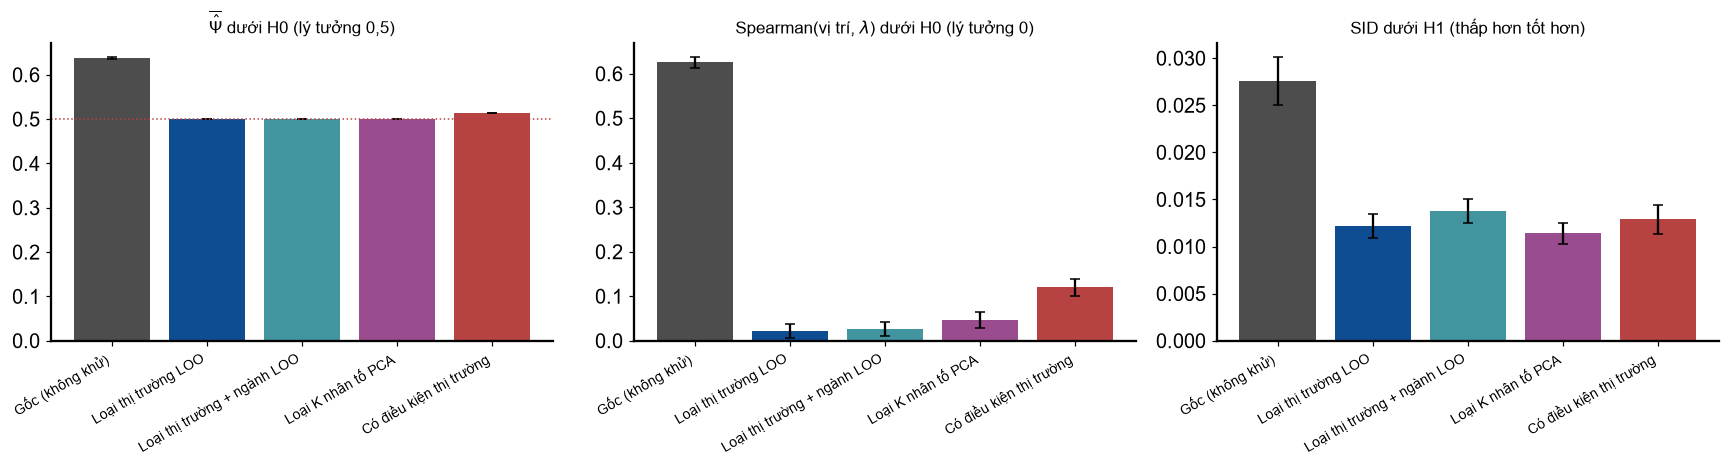

psi_TB       rho_lambda        SID      
gia_thuyet      H0    H1         H0     H1  H0    H1
phuong_phap                                         
raw          0.637 0.638      0.625  0.483 NaN 0.028
loo          0.501 0.506      0.022 -0.002 NaN 0.012
loo_sector   0.501 0.506      0.025 -0.000 NaN 0.014
pca          0.501 0.506      0.046 -0.004 NaN 0.011
conditional  0.514 0.517      0.120  0.053 NaN 0.013

In [2]:
def one(child, h1):
    rng_ = np.random.default_rng(child)
    A_ = CT.random_dag(P, rng_, edge_prob=EDGE_PROB) if h1 else np.zeros((P, P), int)
    Bc = A_ * rng_.uniform(0.2, 0.5, (P, P)) if h1 else None
    X = pd.DataFrame(V.simulate_factor_scm(n, lam, NU, B_coef=Bc, rng=rng_), columns=SYMBOLS)
    out = []
    for m in METHODS:
        M = C.method_matrix(X, m, k=KC, K=1, sector=SECTOR, corr="pearson")
        o = CT.ease(M); pos = [o.index(s) + 1 for s in SYMBOLS]
        out.append({"gia_thuyet": "H1" if h1 else "H0", "phuong_phap": m, "psi_TB": float(np.nanmean(M.values[OFF])),
                    "rho_lambda": stats.spearmanr(pos, lam)[0],
                    "SID": CT.sid(A_, CT.order_to_adjacency([SYMBOLS.index(s) for s in o])) if h1 else np.nan})
    return out

kids = np.random.SeedSequence(77).spawn(120)
rows = Parallel(n_jobs=-1)(delayed(one)(c, i >= 60) for i, c in enumerate(kids))
sim = pd.DataFrame([x for rr in rows for x in rr])
U.save_table(sim, "02_deconfounding_sim", FOLDER)
summ = sim.groupby(["phuong_phap", "gia_thuyet"]).agg(psi_TB=("psi_TB", "mean"), rho_lambda=("rho_lambda", "mean"),
                                                        SID=("SID", "mean")).unstack()
summ = summ.reindex(METHODS)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
x = np.arange(len(METHODS)); names = [LAB[m] for m in METHODS]
cm = [PAL["gray_dark"], PAL["blue_main"], PAL["teal"], PAL["violet"], PAL["red_strong"]]
for ax, (col, h, title, ref) in zip(axes, [("psi_TB", "H0", r"$\overline{\hat\Psi}$ dưới H0 (lý tưởng 0,5)", 0.5),
                                           ("rho_lambda", "H0", r"Spearman(vị trí, $\lambda$) dưới H0 (lý tưởng 0)", 0),
                                           ("SID", "H1", "SID dưới H1 (thấp hơn tốt hơn)", None)]):
    d = sim[sim.gia_thuyet == h].groupby("phuong_phap")[col].agg(["mean", "sem"]).reindex(METHODS)
    ax.bar(x, d["mean"], yerr=d["sem"], color=cm, capsize=3)
    if ref is not None:
        ax.axhline(ref, color=PAL["red_strong"], ls=":", lw=1)
    ax.set_xticks(x, names, rotation=30, ha="right", fontsize=9); ax.set_title(title, fontsize=11)
U.finalize_figure(fig, "02_deconfounding_sim", folder=FOLDER); plt.show()
summ.round(3)

### Phân tích

- **Không khử (raw)** lặp lại vấn đề của Validation: dưới H0, $\overline{\hat\Psi}$ = 0,64 (thay vì 0,5) và thứ tự tương quan **ρ = 0,63** với tải $\lambda$ — thứ tự giả; SID dưới H1 = 0,028.
- **Mọi phương pháp khử đều đưa $\overline{\hat\Psi}$ về 0,50–0,52.** Với 60 mã, LOO, LOO+ngành và PCA xoá gần hết thứ tự theo tải (ρ = 0,02–0,05, trong ~2 sai số chuẩn của 0);
  **hệ số có điều kiện còn lệch** (ρ = 0,12 ± 0,02, $\overline{\hat\Psi}$ = 0,514).
- **Dưới H1, các phương pháp khử ngang nhau:** SID 0,011 (PCA), 0,012 (LOO), 0,013 (có điều kiện), 0,014 (LOO+ngành) — chênh lệch trong ~1 sai số chuẩn (0,001–0,0015), đều bằng một nửa raw.
- **Khác kết quả 20 mã:** khi đó hệ số có điều kiện tốt nhất và LOO+ngành phản tác dụng. Với 60 mã, nhân tố thị trường LOO và PCA được ước lượng từ nhiều mã hơn nên chính xác hơn,
  và ngành có nhiều mã hơn nên nhân tố ngành LOO bớt nhiễu — lợi thế của cách "có điều kiện" (không cần ước lượng tải) biến mất.

## 2. Áp dụng lên dữ liệu thật

**Tính gì:** với mỗi phương pháp: $\overline{\hat\Psi}$, $\overline{\hat\Psi}$ trong cùng ngành / khác ngành, Spearman giữa vị trí EASE và hệ số tải $\hat\lambda$,
và thứ tự EASE (5 mã đầu, 3 mã cuối).

In [3]:
sec = np.array([SECTOR[s] for s in SYMBOLS]); same = (sec[:, None] == sec[None, :]) & OFF
real, mats = [], {}
for m in METHODS:
    M = C.method_matrix(z, m, k=KC, K=1, sector=SECTOR, corr="kendall"); mats[m] = M
    o = CT.ease(M); pos = [o.index(s) + 1 for s in SYMBOLS]
    real.append({"phuong_phap": LAB[m], "psi_TB": np.nanmean(M.values[OFF]), "cung_nganh": np.nanmean(M.values[same]),
                 "khac_nganh": np.nanmean(M.values[OFF & ~same]), "rho_lambda": stats.spearmanr(pos, lam)[0],
                 "5_dau": " → ".join(o[:5]), "3_cuoi": " → ".join(o[-3:])})
real = pd.DataFrame(real).set_index("phuong_phap")
U.save_table(real, "02_real_methods", FOLDER)
pd.set_option("display.max_colwidth", 70)
real.round(3)

,psi_TB,cung_nganh,khac_nganh,rho_lambda,5_dau,3_cuoi
phuong_phap,,,,,,
Gốc (không khử),0.667,0.703,0.661,0.638,NVL → VJC → EIB → VNM → CTD,VCI → HCM → SSI
Loại thị trường LOO,0.544,0.578,0.539,0.357,DGC → MSN → FRT → TCM → DXG,TCB → MBB → CTG
Loại thị trường + ngành LOO,0.539,0.576,0.533,0.301,HDG → HAG → DGW → PVD → HAH,DCM → HPG → HSG
Loại K nhân tố PCA,0.545,0.578,0.540,0.322,MSN → HAG → DXG → FRT → CII,CTG → DPM → DCM
Có điều kiện thị trường,0.552,0.603,0.544,0.517,SAB → FRT → TCM → VJC → HDG,VPB → SSI → HCM


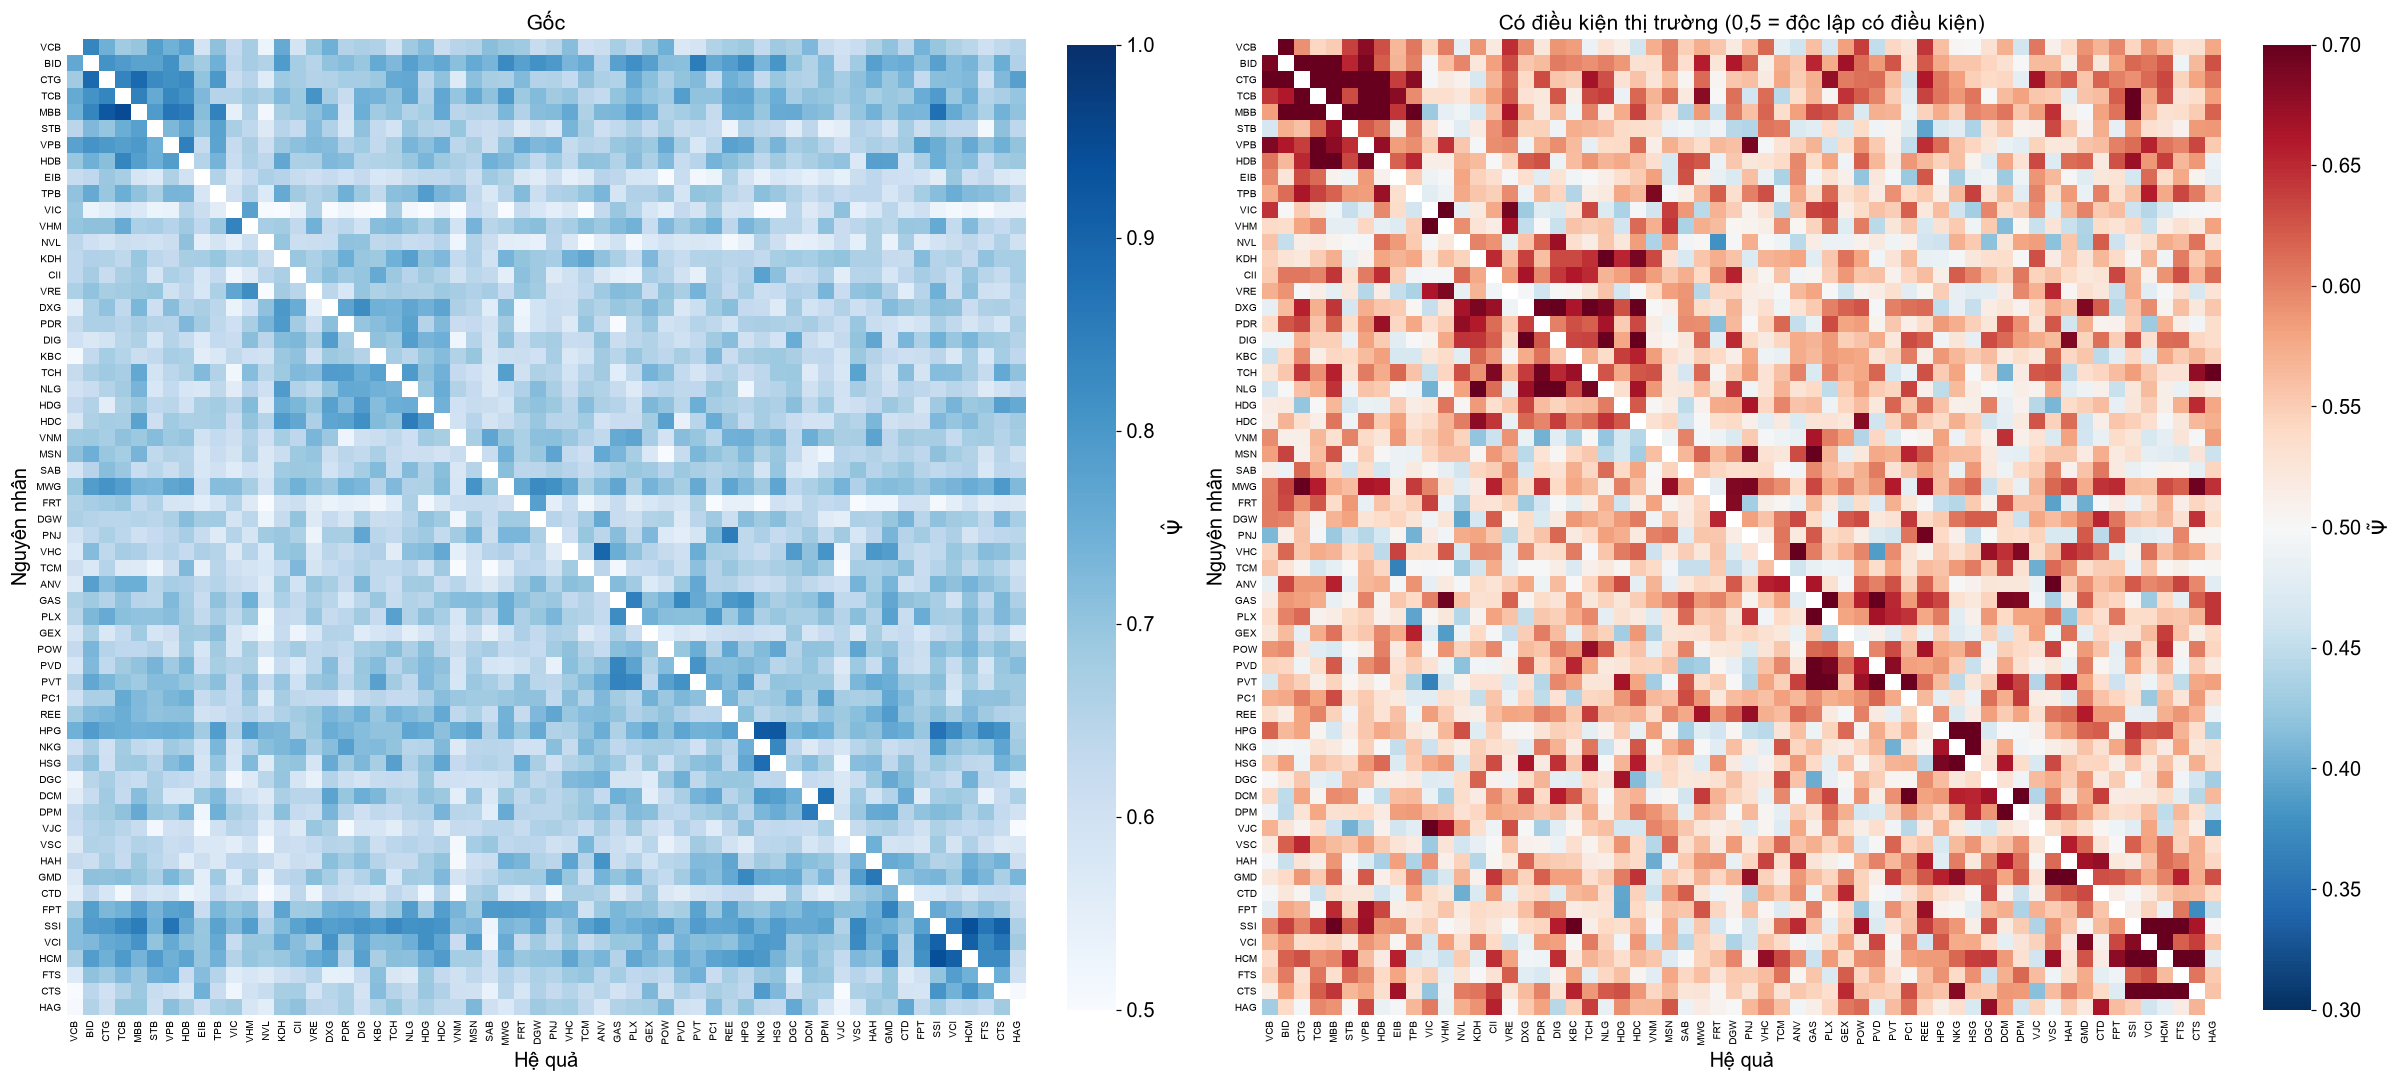

10 hệ số có điều kiện lớn nhất: {'MBB→TCB': 0.858, 'HSG→NKG': 0.855, 'SSI→HCM': 0.841, 'VHC→ANV': 0.836, 'CTG→MBB': 0.829, 'DCM→DPM': 0.827, 'HPG→HSG': 0.819, 'MBB→VPB': 0.815, 'VHM→VIC': 0.808, 'HPG→NKG': 0.806}


In [4]:
CHOSEN = "conditional"
M = mats[CHOSEN]
fig, axes = plt.subplots(1, 2, figsize=(22, 10))
U.make_heatmap(axes[0], mats["raw"], cmap="Blues", vmin=0.5, vmax=1, fmt=None, tick_fontsize=6.5, cbar_label=r"$\hat\Psi$", title="Gốc")
U.make_heatmap(axes[1], M, cmap="RdBu_r", vmin=0.3, vmax=0.7, fmt=None, tick_fontsize=6.5, cbar_label=r"$\tilde\Psi$",
               title="Có điều kiện thị trường (0,5 = độc lập có điều kiện)")
for ax in axes:
    ax.set_xlabel("Hệ quả"); ax.set_ylabel("Nguyên nhân")
U.finalize_figure(fig, "02_conditional_matrix", folder=FOLDER); plt.show()
st = M.stack().dropna().sort_values(ascending=False)
print("10 hệ số có điều kiện lớn nhất:", {f"{a}→{b}": round(v, 3) for (a, b), v in st.head(10).items()})

## 3. Độ tin cậy của các hệ số có điều kiện lớn nhất

**Tính gì:** bootstrap theo khối (moving block, khối $\lceil\sqrt n\rceil$ phiên, $B = 200$) của ma trận có điều kiện; khoảng 90% cho các hệ số lớn nhất và cho bất đối xứng
$D_{jl} = \tilde\Psi_{jl} - \tilde\Psi_{lj}$ của các cặp đó. Bootstrap khối giữ phụ thuộc thời gian còn sót sau lọc GARCH.

In [5]:
def block_boot(b):
    rng_ = np.random.default_rng(1000 + b); L = int(np.ceil(np.sqrt(n)))
    st_ = rng_.integers(0, n - L + 1, int(np.ceil(n / L)))
    ix = (st_[:, None] + np.arange(L)).ravel()[:n]
    return C.adjusted_tail_coef_matrix(z.iloc[ix], k=KC, seed=b)["adj"].to_numpy()

boot = np.array(Parallel(n_jobs=-1)(delayed(block_boot)(b) for b in range(200)))
top = st.head(12)
rows = []
for (a, b), v in top.items():
    i, j = SYMBOLS.index(a), SYMBOLS.index(b)
    dd = boot[:, i, j] - boot[:, j, i]
    rows.append({"cap": f"{a}→{b}", "nganh": f"{SECTOR[a]} → {SECTOR[b]}", "psi_dk": v,
                 "q05": np.nanquantile(boot[:, i, j], 0.05), "q95": np.nanquantile(boot[:, i, j], 0.95),
                 "D": M.loc[a, b] - M.loc[b, a], "D_q05": np.nanquantile(dd, 0.05), "D_q95": np.nanquantile(dd, 0.95)})
topt = pd.DataFrame(rows).set_index("cap")
topt["vuot_0.5"] = topt.q05 > 0.5; topt["co_chieu"] = (topt.D_q05 > 0) | (topt.D_q95 < 0)
U.save_table(topt, "02_top_conditional", FOLDER)
topt.round(3)

,nganh,psi_dk,q05,q95,D,D_q05,D_q95,vuot_0.5,co_chieu
cap,,,,,,,,,
MBB→TCB,Ngân hàng → Ngân hàng,0.858,0.780,0.912,0.084,-0.010,0.130,True,False
HSG→NKG,Thép → Thép,0.855,0.738,0.908,0.068,-0.057,0.173,True,False
SSI→HCM,Chứng khoán → Chứng khoán,0.841,0.794,0.910,0.041,-0.029,0.125,True,False
VHC→ANV,Tiêu dùng → Tiêu dùng,0.836,0.761,0.896,0.181,0.062,0.284,True,True
CTG→MBB,Ngân hàng → Ngân hàng,0.829,0.768,0.905,0.030,-0.082,0.098,True,False
DCM→DPM,Hoá chất → Hoá chất,0.827,0.774,0.909,0.072,-0.037,0.152,True,False
HPG→HSG,Thép → Thép,0.819,0.685,0.873,0.129,0.018,0.221,True,True
MBB→VPB,Ngân hàng → Ngân hàng,0.815,0.720,0.865,0.136,0.011,0.228,True,True
VHM→VIC,Bất động sản → Bất động sản,0.808,0.705,0.883,0.041,-0.044,0.137,True,False


### Phân tích

- Trên dữ liệu thật, khử nhân tố đưa $\overline{\hat\Psi}$ từ 0,67 về 0,54–0,55. Tương quan giữa thứ tự và tải: raw 0,64 → LOO 0,36 → PCA 0,32 → LOO+ngành 0,30 →
  có điều kiện 0,52. Mọi phương pháp còn giữ ρ = 0,30–0,52, cao hơn nhiều mức 0,02–0,12 chúng cho dưới H0 — dữ liệu thật có cấu trúc **ngoài** một nhân tố:
  các ngành hẹp (chứng khoán, ngân hàng, thép, phân bón) vừa tải cao vừa phụ thuộc đuôi mạnh với nhau.
- **Phụ thuộc đuôi còn lại tập trung trong các ngành hẹp:** cùng ngành 0,603 so với khác ngành 0,544 (phương pháp có điều kiện). **12/12 hệ số lớn nhất đều trong cùng ngành**: MBB→TCB 0,86,
  HSG→NKG 0,86, SSI→HCM 0,84, VHC→ANV 0,84 (thuỷ sản), CTG→MBB 0,83, DCM→DPM 0,83, HPG→HSG 0,82, MBB→VPB 0,82, VHM→VIC 0,81; mọi khoảng 90% đều trên 0,5.
- **Chiều:** 5/12 cặp có bất đối xứng với khoảng bootstrap khối 90% không chứa 0: **VHC → ANV** ($D$ = +0,18, [0,06; 0,28]), HPG → NKG (+0,14), MBB → VPB (+0,14), HPG → HSG (+0,13),
  TCB → VPB (+0,10). Đáng chú ý: **HPG (thép lớn) dẫn hai mã tôn thép nhỏ**, và **ngân hàng lớn dẫn VPB**. Đây là kiểm định từng cặp, chưa hiệu chỉnh đa so sánh — gợi ý, chưa phải bằng chứng.
  Gợi ý MBB → TCB của giai đoạn 20 mã không còn đứng vững ($D$ = +0,08, [−0,01; 0,13]).
- Thứ tự EASE có điều kiện: SAB → FRT → TCM → VJC → HDG … → VPB → SSI → HCM. Chứng khoán và ngân hàng vẫn ở cuối, vì **phụ thuộc đuôi trong ngành**.

## 4. Kết luận

1. **Khử nhân tố là bắt buộc** trước EASE: không khử, thứ tự gần như là thứ tự hệ số tải (ρ = 0,63 dưới H0, 0,64 trên dữ liệu thật).
2. Với 60 mã, **các cách khử cho SID ngang nhau** (0,011–0,014); PCA và LOO xoá thứ tự giả tốt nhất dưới H0, hệ số có điều kiện còn lệch nhẹ (ρ = 0,12).
   Khác giai đoạn 20 mã, loại thêm nhân tố ngành LOO không còn phản tác dụng.
3. Sau khi khử, phụ thuộc đuôi còn lại là **trong ngành hẹp** (ngân hàng, thép, chứng khoán, phân bón, thuỷ sản, Vingroup); có gợi ý chiều HPG → NKG/HSG, ngân hàng lớn → VPB,
   VHC → ANV nhưng chưa qua hiệu chỉnh đa so sánh.